# NN_L5_load_window

**Test MAPE of the day-ahead LSTM for Romanian load as a function of the input window (24, 72, 168, 336 hours), 2 seeds each, against ridge ARX.**

Neural Networks and Deep Learning (NN), Lecture 5 · Daniel Traian Pele, Bucharest University of Economic Studies

[Open in Colab](https://colab.research.google.com/github/danpele/NEURAL_BIZ/blob/main/Quantlets/L5/NN_L5_load_window/NN_L5_load_window.ipynb)

In [1]:
import os
# course data: the local copy of the repository if there is one, else the public repository on GitHub
_LOCAL = os.path.join('..', '..', '..', 'data', 'clean')
DATA = _LOCAL + os.sep if os.path.isdir(_LOCAL) else 'https://raw.githubusercontent.com/danpele/NEURAL_BIZ/main/data/clean/'
REPO = os.path.join('..', '..', '..') + os.sep if os.path.isdir(_LOCAL) else 'https://raw.githubusercontent.com/danpele/NEURAL_BIZ/main/'

In [2]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings('ignore')
# course chart style: transparent background, no gridlines, legend at the bottom outside the axes, four-digit years
plt.rcParams.update({
    'figure.facecolor': 'none', 'axes.facecolor': 'none', 'savefig.transparent': True,
    'axes.grid': False, 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.edgecolor': '#222222', 'axes.labelcolor': '#222222', 'xtick.color': '#222222', 'ytick.color': '#222222',
    'text.color': '#222222', 'font.size': 11, 'axes.labelsize': 11, 'legend.fontsize': 10.5, 'legend.frameon': False,
    'lines.linewidth': 1.4, 'font.family': 'DejaVu Sans'})
SERIES = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4', '#008300', '#6250d6', '#e34948']
PAL = {'data': '#2a78d6', 'model': '#eb6834', 'benchmark': '#1baf7a', 'alt': '#eda100',
       'train': '#2a78d6', 'valid': '#eb6834', 'test': '#6250d6', 'positive': '#e34948', 'negative': '#2a78d6'}


def legend_bottom(fig, ncol=4):
    h, l_ = [], []
    for ax in fig.axes:
        for hh, ll in zip(*ax.get_legend_handles_labels()):
            if ll not in l_:
                h.append(hh); l_.append(ll)
    if h:
        fig.legend(h, l_, loc='lower center', ncol=min(ncol, len(h)), bbox_to_anchor=(0.5, 0.0), frameon=False)


def show(key, label, value):
    # print a number of the slide; [key] = its name in lectures/Lk/Lk_numbers.json
    print(f'{label} = {value}   [{key}]')

How much history does the LSTM need?

MAPE, window 24 hours (%) = 6.77   [load.window.24]
MAPE, window 72 hours (%) = 7.17   [load.window.72]
MAPE, window 168 hours (%) = 5.91   [load.window.168]
MAPE, window 336 hours (%) = 5.93   [load.window.336]


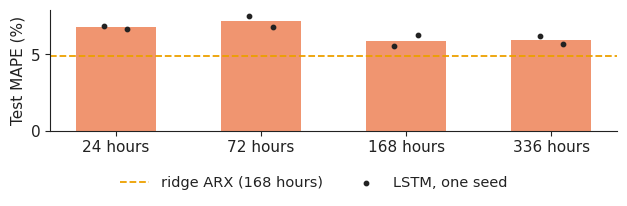

In [3]:
import json, urllib.request
_F = 'load_window_results.json'
R = json.load(open(_F)) if os.path.isfile(_F) else json.load(urllib.request.urlopen(REPO + 'Quantlets/L5/NN_L5_load_window/' + _F))
for w in ['24', '72', '168', '336']: show(f'load.window.{w}', f'MAPE, window {w} hours (%)', round(float(np.mean(R['win'][w])), 2))
fig, ax = plt.subplots(figsize=(6.4, 2.1)); ws = ['24', '72', '168', '336']
for i, w in enumerate(ws):
    ax.bar(i, np.mean(R['win'][w]), color=PAL['model'], width=.55, alpha=.7); ax.scatter([i - .08, i + .08], R['win'][w], color='#222222', s=10, zorder=3)
ax.axhline(R['ridge'], color=PAL['alt'], ls='--', lw=1.3, label='ridge ARX (168 hours)'); ax.set_xticks(range(4)); ax.set_xticklabels([w + ' hours' for w in ws])
ax.set_ylabel('Test MAPE (%)'); ax.scatter([], [], color='#222222', s=10, label='LSTM, one seed'); legend_bottom(fig, ncol=2); fig.tight_layout(rect=(0, .15, 1, 1))
fig.savefig('load_window.png', dpi=200, transparent=True, bbox_inches='tight')
plt.show()